# Coral Bleaching Detector
**21CEO310T – Global Warming and Climate Change | LLT / CLA-2 machine-learning project**

This notebook trains a deep-learning model that looks at a photo of coral and decides whether it is **healthy** or **bleached**. It then shows *which parts of the photo* led to that decision, using a technique called Grad-CAM.

**Why it matters for climate change.** Corals get their colour and most of their food from microscopic algae (*zooxanthellae*) living inside their tissue. When seawater stays unusually warm for weeks, the partnership breaks down: the coral expels the algae and its white limestone skeleton shows through. This is **coral bleaching**. A bleached coral is not dead yet and can recover if the water cools, but long or repeated heat stress starves it. The ocean has absorbed more than 90% of the extra heat trapped by greenhouse gases, so marine heatwaves and mass bleaching events are becoming more frequent. Reefs support fisheries, protect coastlines from waves and drive tourism (Unit III). In India they are found in the Gulf of Mannar, Gulf of Kutch, Lakshadweep and the Andaman & Nicobar Islands.

**ML approach.** Transfer learning with **MobileNetV2**, a CNN pre-trained on 1.4 million everyday photos (ImageNet). It is fine-tuned on the Kaggle dataset *Healthy and Bleached Corals Image Classification*, which has 923 real photos (438 healthy, 485 bleached). A **test set the model never sees during training** is kept aside, so the reported results are honest.

### How to run (about 10–15 minutes)
1. `Runtime → Change runtime type → T4 GPU → Save`
2. `Runtime → Run all`
3. When it finishes, **`coral_outputs.zip`** downloads automatically. It contains the trained model, every figure for your report and the final numbers.

## 0. Settings and libraries

In [1]:
# ---- Settings you can change ----
KAGGLE_DATASET = "vencerlanz09/healthy-and-bleached-corals-image-classification"
LOCAL_DATA_DIR = None    # If you downloaded the dataset yourself, put its folder path here, e.g. "/content/corals"
IMG_SIZE = 224           # MobileNetV2 input size (pixels)
BATCH_SIZE = 32
EPOCHS_HEAD = 20         # Stage 1: train only the new classifier layer (early stopping may end it sooner)
EPOCHS_FINETUNE = 15     # Stage 2: also fine-tune the top layers of MobileNetV2 (early stopping usually ends it sooner)
FINETUNE_LAYERS = 30     # How many of MobileNetV2's top layers to unfreeze in Stage 2
LABEL_SMOOTHING = 0.05   # Softens the 0/1 targets slightly, which helps with noisy internet labels and over-confidence
USE_TTA = True           # Test-time augmentation: average the prediction for the photo and its mirror image
TUNE_THRESHOLD = True    # Pick the decision threshold on the validation set instead of always using 0.5
SEED = 42                # Fixed random seed so results are repeatable
OUTPUT_DIR = "coral_outputs"
RUN_GRADIO_DEMO = False  # Set to True to launch a live web demo inside Colab (Step 11)

In [2]:
import os, sys, json, time, hashlib, random, shutil, subprocess
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve)

random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    # Charts are saved as PNG (sharp lines); photo grids as JPEG (much smaller files for your report).
    path = os.path.join(FIG_DIR, name)
    extra = {"pil_kwargs": {"quality": 90}} if name.endswith(".jpg") else {}
    plt.savefig(path, dpi=150, bbox_inches="tight", **extra)
    print("Saved figure:", path)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none found, so training will be slower (see Runtime → Change runtime type)")

TensorFlow 2.21.0 | Keras 3.15.1
GPU: none found, so training will be slower (see Runtime → Change runtime type)


## 1. Download the dataset
The dataset is downloaded straight from Kaggle with `kagglehub`. If Kaggle asks you to log in, follow the README: either add your Kaggle API token, or download the zip yourself, upload it to Colab and set `LOCAL_DATA_DIR`.

In [3]:
if LOCAL_DATA_DIR:
    raw_dir = LOCAL_DATA_DIR
else:
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    raw_dir = kagglehub.dataset_download(KAGGLE_DATASET)

print("Dataset folder:", raw_dir)
for root, dirs, files in os.walk(raw_dir):
    depth = os.path.relpath(root, raw_dir).count(os.sep)
    if depth < 3:
        print("  " * depth + os.path.basename(root) + f"/  ({len(files)} files)")

c:\Users\saxen\Downloads\coral_bleaching_detector_improved\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 25.8M/25.8M [00:08<00:00, 3.05MB/s]

Extracting files...


Dataset folder: C:\Users\saxen\.cache\kagglehub\datasets\vencerlanz09\healthy-and-bleached-corals-image-classification\versions\1
1/  (0 files)
bleached_corals/  (485 files)
healthy_corals/  (438 files)


## 2. Clean and organise the images
Real-world data is messy, so this step:
- **labels** each photo from the name of the folder it is in (`healthy…` → 0, `bleached…` → 1)
- **removes exact duplicate photos**, so the same picture can't end up in both training and test data (that would inflate the score)
- **skips broken files** and converts every image to a standard RGB JPEG
- **rotates photos upright** using their camera (EXIF) orientation tag, exactly as the web app does, so training and the live demo see photos the same way up

In [4]:
IMG_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".gif", ".tif", ".tiff", ".avif")
CLASS_NAMES = ["healthy", "bleached"]   # label 0 = healthy, label 1 = bleached

def label_from_path(path):
    # Look at the folder names inside the dataset (nearest folder first).
    rel_dir = os.path.relpath(os.path.dirname(path), raw_dir)
    for part in reversed(rel_dir.split(os.sep)):
        p = part.lower()
        if "unbleach" in p or "healthy" in p:
            return 0
        if "bleach" in p:
            return 1
    return None

CLEAN_DIR = "coral_data_clean"
shutil.rmtree(CLEAN_DIR, ignore_errors=True)
for c in CLASS_NAMES:
    os.makedirs(os.path.join(CLEAN_DIR, c))

seen, paths, labels = set(), [], []
skipped = {"no class folder": 0, "duplicate": 0, "unreadable": 0}
for root, _, files in os.walk(raw_dir):
    for name in sorted(files):
        if not name.lower().endswith(IMG_EXTS):
            continue
        src = os.path.join(root, name)
        label = label_from_path(src)
        if label is None:
            skipped["no class folder"] += 1
            continue
        with open(src, "rb") as f:
            digest = hashlib.md5(f.read()).hexdigest()
        if digest in seen:
            skipped["duplicate"] += 1
            continue
        try:
            img = ImageOps.exif_transpose(Image.open(src)).convert("RGB")   # upright, like the app
            img.thumbnail((512, 512))   # shrink very large photos to speed up training
        except Exception:
            skipped["unreadable"] += 1
            continue
        seen.add(digest)
        dst = os.path.join(CLEAN_DIR, CLASS_NAMES[label], digest[:16] + ".jpg")
        img.save(dst, quality=95)
        paths.append(dst)
        labels.append(label)

paths, labels = np.array(paths), np.array(labels)
counts = {c: int((labels == i).sum()) for i, c in enumerate(CLASS_NAMES)}
assert min(counts.values()) > 0, f"Could not find both classes. Check the folder names under {raw_dir}"
print("Usable images:", len(paths), counts)
print("Skipped:", skipped)

Usable images: 905 {'healthy': 423, 'bleached': 482}
Skipped: {'no class folder': 0, 'duplicate': 18, 'unreadable': 0}


## 3. Explore the data

Saved figure: coral_outputs\figures\01_class_balance.png


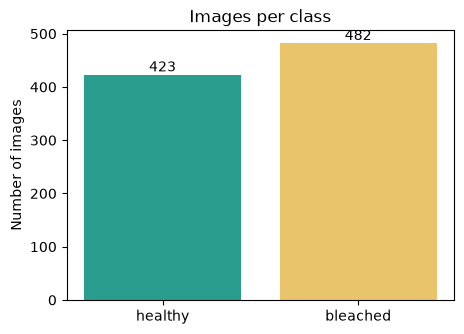

Saved figure: coral_outputs\figures\02_sample_images.jpg


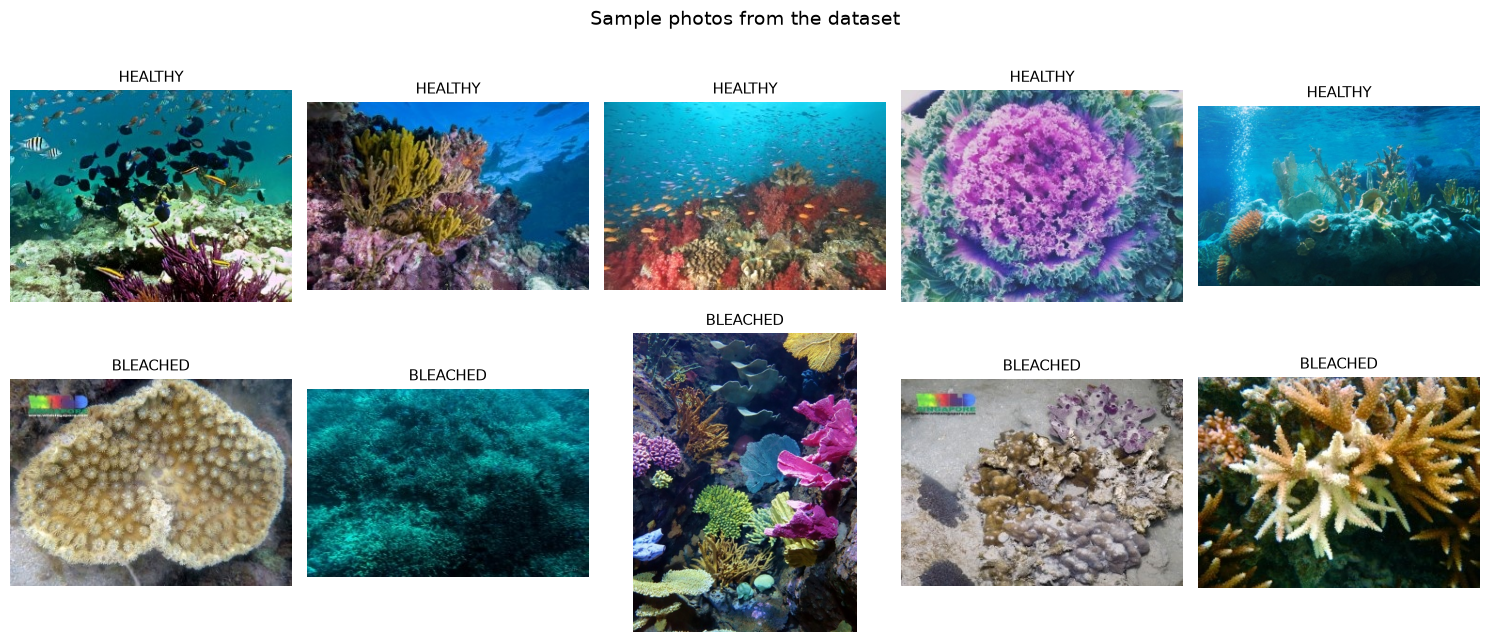

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(CLASS_NAMES, counts.values(), color=["#2a9d8f", "#e9c46a"])
ax.bar_label(bars)
ax.set_ylabel("Number of images")
ax.set_title("Images per class")
save_fig("01_class_balance.png")
plt.show()

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for row, cls in enumerate(CLASS_NAMES):
    choice = rng.choice(paths[labels == row], size=min(5, counts[cls]), replace=False)
    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(choice):
            ax.imshow(Image.open(choice[col]))
            ax.set_title(cls.upper(), fontsize=11)
plt.suptitle("Sample photos from the dataset", fontsize=14)
plt.tight_layout()
save_fig("02_sample_images.jpg")
plt.show()

## 4. Split into training, validation and test sets
- **Training (70%)**: the model learns from these.
- **Validation (15%)**: used during training to decide when to stop.
- **Test (15%)**: locked away until the very end and used only once, for the final score.

The split is *stratified*, so each set keeps the same healthy:bleached ratio.

In [6]:
train_p, temp_p, train_y, temp_y = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(temp_p, temp_y, test_size=0.50, stratify=temp_y, random_state=SEED)
for name, y in [("Train", train_y), ("Validation", val_y), ("Test", test_y)]:
    print(f"{name:<11} {len(y):>4} images  (healthy {int((y == 0).sum())}, bleached {int((y == 1).sum())})")

def load_image(path, label):
    img = tf.image.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))   # float32, pixel values 0–255
    return img, tf.reshape(tf.cast(label, tf.float32), [1])

def make_dataset(p, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if shuffle:
        ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_p, train_y, shuffle=True)
val_ds = make_dataset(val_p, val_y)
test_ds = make_dataset(test_p, test_y)   # not shuffled, so predictions line up with test_y

Train        633 images  (healthy 296, bleached 337)
Validation   136 images  (healthy 63, bleached 73)
Test         136 images  (healthy 64, bleached 72)


## 5. Build the model (transfer learning)
Training a CNN from scratch needs a huge number of photos. Instead we reuse **MobileNetV2**, which already knows how to detect edges, textures and colours from ImageNet, and add one new output neuron that gives the *probability that the coral is bleached*.

**Data augmentation:** during training, each photo is randomly flipped, rotated, zoomed and shifted, so the model sees a slightly different version every epoch and doesn't memorise the training set. We deliberately do **not** change brightness or colour, because colour loss is the main symptom of bleaching.

In [7]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

base_model = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                            include_top=False, weights="imagenet")
base_model.trainable = False   # Stage 1: freeze the pre-trained layers

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
x = augmentation(inputs)                                    # only active during training
x = layers.Rescaling(1 / 127.5, offset=-1, name="rescale")(x)  # MobileNetV2 expects pixels in [-1, 1]
x = base_model(x, training=False)                           # run MobileNetV2 in inference mode
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3, name="dropout")(x)
outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)
model = keras.Model(inputs, outputs, name="coral_bleaching_detector")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "coral_bleaching_detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Train in two stages
1. **Stage 1:** train only the new output layer (fast, learning rate 0.001).
2. **Stage 2 (fine-tuning):** unfreeze the top 30 layers of MobileNetV2 (except its BatchNorm layers) and train them gently (learning rate 0.00001), so they adapt to underwater coral images.

*Early stopping* watches the validation loss and stops training when it stops improving, keeping the best weights. If the validation loss stalls for two epochs, the learning rate is also cut to a third (*ReduceLROnPlateau*) so the model can settle into a better minimum before stopping. A small amount of *label smoothing* stops the model from becoming over-confident on the small, noisy dataset.

In [8]:
def make_metrics():
    return ["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")]

def make_callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1)]

loss_fn = keras.losses.BinaryCrossentropy(label_smoothing=LABEL_SMOOTHING)

t0 = time.time()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=make_metrics())
history1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, verbose=2, callbacks=make_callbacks())

base_model.trainable = True
for layer in base_model.layers[:-FINETUNE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers[-FINETUNE_LAYERS:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False   # keep BatchNorm frozen, otherwise it uses per-batch statistics and destabilises training
model.compile(optimizer=keras.optimizers.Adam(1e-5), loss=loss_fn, metrics=make_metrics())
stage1_epochs = len(history1.history["loss"])
history2 = model.fit(train_ds, validation_data=val_ds, epochs=stage1_epochs + EPOCHS_FINETUNE,
                     initial_epoch=stage1_epochs, verbose=2, callbacks=make_callbacks())
stage2_epochs = len(history2.history["loss"])
train_minutes = (time.time() - t0) / 60
print(f"Training time: {train_minutes:.1f} minutes")

Epoch 1/20


c:\Users\saxen\Downloads\coral_bleaching_detector_improved\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 - 37s - 2s/step - accuracy: 0.5134 - loss: 0.7737 - precision: 0.5457 - recall: 0.5134 - val_accuracy: 0.5735 - val_loss: 0.6816 - val_precision: 0.6027 - val_recall: 0.6027 - learning_rate: 0.0010
Epoch 2/20
20/20 - 23s - 1s/step - accuracy: 0.6272 - loss: 0.6566 - precision: 0.6407 - recall: 0.6825 - val_accuracy: 0.6471 - val_loss: 0.6359 - val_precision: 0.6623 - val_recall: 0.6986 - learning_rate: 0.0010
Epoch 3/20
20/20 - 19s - 965ms/step - accuracy: 0.6714 - loss: 0.6195 - precision: 0.6848 - recall: 0.7092 - val_accuracy: 0.6691 - val_loss: 0.6139 - val_precision: 0.6892 - val_recall: 0.6986 - learning_rate: 0.0010
Epoch 4/20
20/20 - 31s - 2s/step - accuracy: 0.7156 - loss: 0.5733 - precision: 0.7249 - recall: 0.7507 - val_accuracy: 0.6691 - val_loss: 0.5989 - val_precision: 0.7000 - val_recall: 0.6712 - learning_rate: 0.0010
Epoch 5/20
20/20 - 34s - 2s/step - accuracy: 0.7346 - loss: 0.5590 - precision: 0.7568 - recall: 0.7389 - val_accuracy: 0.6838 - val_loss: 0.5840 - 

Saved figure: coral_outputs\figures\03_training_curves.png


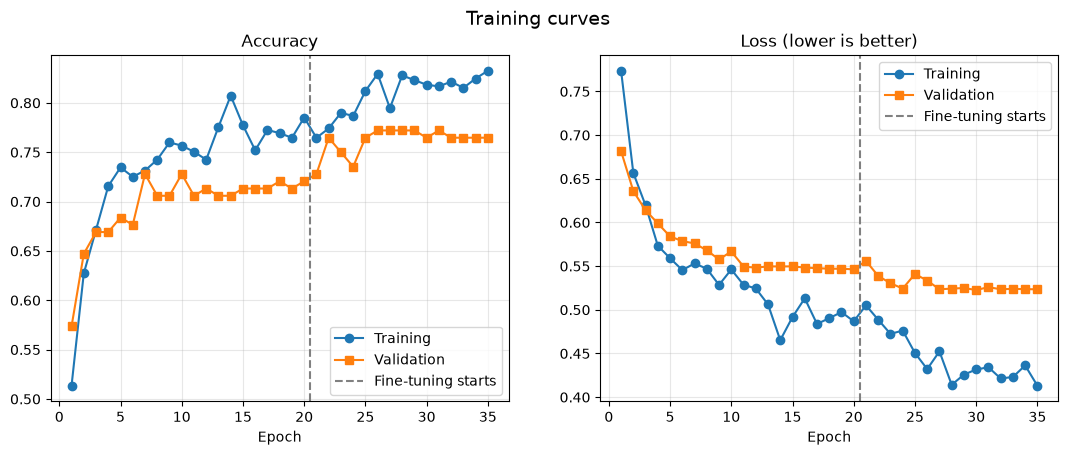

In [9]:
hist = {k: history1.history[k] + history2.history.get(k, []) for k in history1.history}
epochs = range(1, len(hist["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss (lower is better)")]:
    ax.plot(epochs, hist[metric], "o-", label="Training")
    ax.plot(epochs, hist["val_" + metric], "s-", label="Validation")
    ax.axvline(stage1_epochs + 0.5, color="grey", linestyle="--", label="Fine-tuning starts")
    ax.set_xlabel("Epoch")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.suptitle("Training curves", fontsize=14)
save_fig("03_training_curves.png")
plt.show()

## 7. Final evaluation on the unseen test set
This is the honest score: the model has never seen these photos.
- **Precision (bleached):** when the model says "bleached", how often is it right?
- **Recall (bleached):** of all truly bleached corals, how many did it catch?
- **ROC-AUC:** how well it separates the two classes across all thresholds (1.0 = perfect, 0.5 = random guessing).

Two small, cheap tricks make the final prediction a little more reliable:
- **Test-time augmentation (TTA):** each photo is scored twice, as it is and mirrored left-to-right, and the two probabilities are averaged. A coral is still the same coral in a mirror, so this smooths out chance quirks.
- **Decision threshold chosen on the validation set:** instead of always saying "bleached" above 50%, we pick the cut-off that gives the best *balanced accuracy* on the validation photos. The test photos are never used for this choice, so the test score stays honest. The web app reads the chosen threshold from `model_info.json`.

Decision threshold: 0.59   (validation balanced accuracy 0.785)
Test accuracy: 0.801   (at the plain 0.5 threshold: 0.787)   ROC-AUC: 0.880

              precision    recall  f1-score   support

     healthy      0.753     0.859     0.803        64
    bleached      0.857     0.750     0.800        72

    accuracy                          0.801       136
   macro avg      0.805     0.805     0.801       136
weighted avg      0.808     0.801     0.801       136

Saved figure: coral_outputs\figures\04_confusion_matrix_and_roc.png


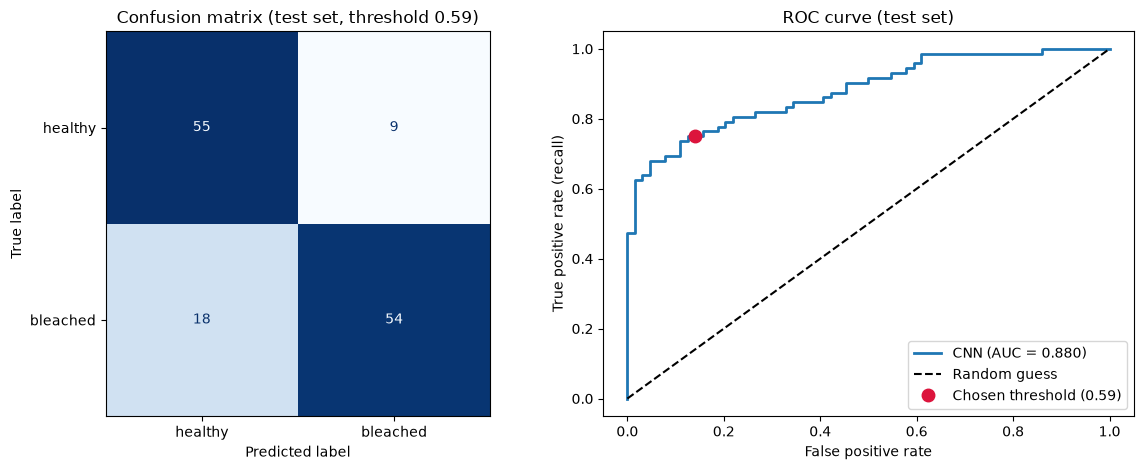

In [10]:
def predict_probs(ds):
    """Probability of "bleached" for every photo in a dataset (with mirror-image TTA if USE_TTA)."""
    probs = model.predict(ds, verbose=0).ravel()
    if USE_TTA:
        mirrored = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
        probs = (probs + model.predict(mirrored, verbose=0).ravel()) / 2
    return probs

# Choose the decision threshold on the VALIDATION set only (never on the test set).
val_probs = predict_probs(val_ds)
THRESHOLD = 0.5
if TUNE_THRESHOLD:
    candidates = np.round(np.arange(0.30, 0.701, 0.01), 2)   # stay near 0.5: the validation set is small
    scores = np.array([balanced_accuracy_score(val_y, (val_probs >= t).astype(int)) for t in candidates])
    best = candidates[np.isclose(scores, scores.max())]
    THRESHOLD = float(best[np.argmin(np.abs(best - 0.5))])  # ties: keep the one closest to 0.5
print(f"Decision threshold: {THRESHOLD:.2f}   (validation balanced accuracy "
      f"{balanced_accuracy_score(val_y, (val_probs >= THRESHOLD).astype(int)):.3f})")

test_probs = predict_probs(test_ds)   # probability of "bleached"
test_pred = (test_probs >= THRESHOLD).astype(int)
test_acc = accuracy_score(test_y, test_pred)
test_acc_at_05 = accuracy_score(test_y, (test_probs >= 0.5).astype(int))
test_auc = roc_auc_score(test_y, test_probs)
report = classification_report(test_y, test_pred, target_names=CLASS_NAMES, digits=3, output_dict=True)

print(f"Test accuracy: {test_acc:.3f}   (at the plain 0.5 threshold: {test_acc_at_05:.3f})   ROC-AUC: {test_auc:.3f}\n")
print(classification_report(test_y, test_pred, target_names=CLASS_NAMES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(confusion_matrix(test_y, test_pred), display_labels=CLASS_NAMES).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix (test set, threshold {THRESHOLD:.2f})")
fpr, tpr, _ = roc_curve(test_y, test_probs)
axes[1].plot(fpr, tpr, lw=2, label=f"CNN (AUC = {test_auc:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
op_fpr = ((test_pred == 1) & (test_y == 0)).sum() / max((test_y == 0).sum(), 1)
op_tpr = ((test_pred == 1) & (test_y == 1)).sum() / max((test_y == 1).sum(), 1)
axes[1].plot(op_fpr, op_tpr, "o", color="crimson", ms=9, label=f"Chosen threshold ({THRESHOLD:.2f})")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve (test set)")
axes[1].legend()
plt.tight_layout()
save_fig("04_confusion_matrix_and_roc.png")
plt.show()

## 8. Is deep learning really needed? A colour-only baseline
Bleached coral is white, so maybe a simple rule like "lots of white pixels = bleached" is enough. We test this by training a basic **logistic regression** (with the features standardised) on 5 colour statistics per photo (average saturation and brightness, their spread, and the fraction of white-ish pixels), using exactly the same train and test split.

Model                                Test accuracy   ROC-AUC
Colour-only logistic regression              0.772     0.840
MobileNetV2 CNN (transfer learning)          0.801     0.880
Saved figure: coral_outputs\figures\05_baseline_vs_cnn.png


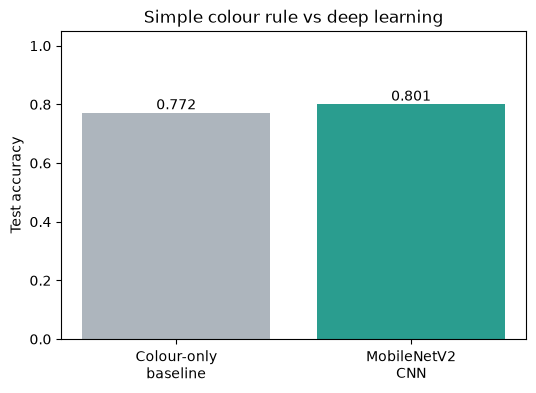

In [11]:
def colour_features(path):
    hsv = np.asarray(Image.open(path).convert("RGB").resize((128, 128)).convert("HSV"), dtype=np.float32) / 255
    s, v = hsv[..., 1], hsv[..., 2]
    white_fraction = ((s < 0.2) & (v > 0.6)).mean()
    return [s.mean(), s.std(), v.mean(), v.std(), white_fraction]

X_train = np.array([colour_features(p) for p in train_p])
X_test = np.array([colour_features(p) for p in test_p])
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, train_y)
baseline_acc = accuracy_score(test_y, baseline.predict(X_test))
baseline_auc = roc_auc_score(test_y, baseline.predict_proba(X_test)[:, 1])

print(f"{'Model':<36}{'Test accuracy':>14}{'ROC-AUC':>10}")
print(f"{'Colour-only logistic regression':<36}{baseline_acc:>14.3f}{baseline_auc:>10.3f}")
print(f"{'MobileNetV2 CNN (transfer learning)':<36}{test_acc:>14.3f}{test_auc:>10.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Colour-only\nbaseline", "MobileNetV2\nCNN"], [baseline_acc, test_acc], color=["#adb5bd", "#2a9d8f"])
ax.bar_label(bars, fmt="%.3f")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Test accuracy")
ax.set_title("Simple colour rule vs deep learning")
save_fig("05_baseline_vs_cnn.png")
plt.show()

## 9. Where is the model looking? (Grad-CAM)
Grad-CAM highlights the regions of a photo that most influenced the prediction (red = strong influence). This lets us check that the model looks at the **coral itself**, not at the water or the background.

Saved figure: coral_outputs\figures\06_gradcam_examples.jpg


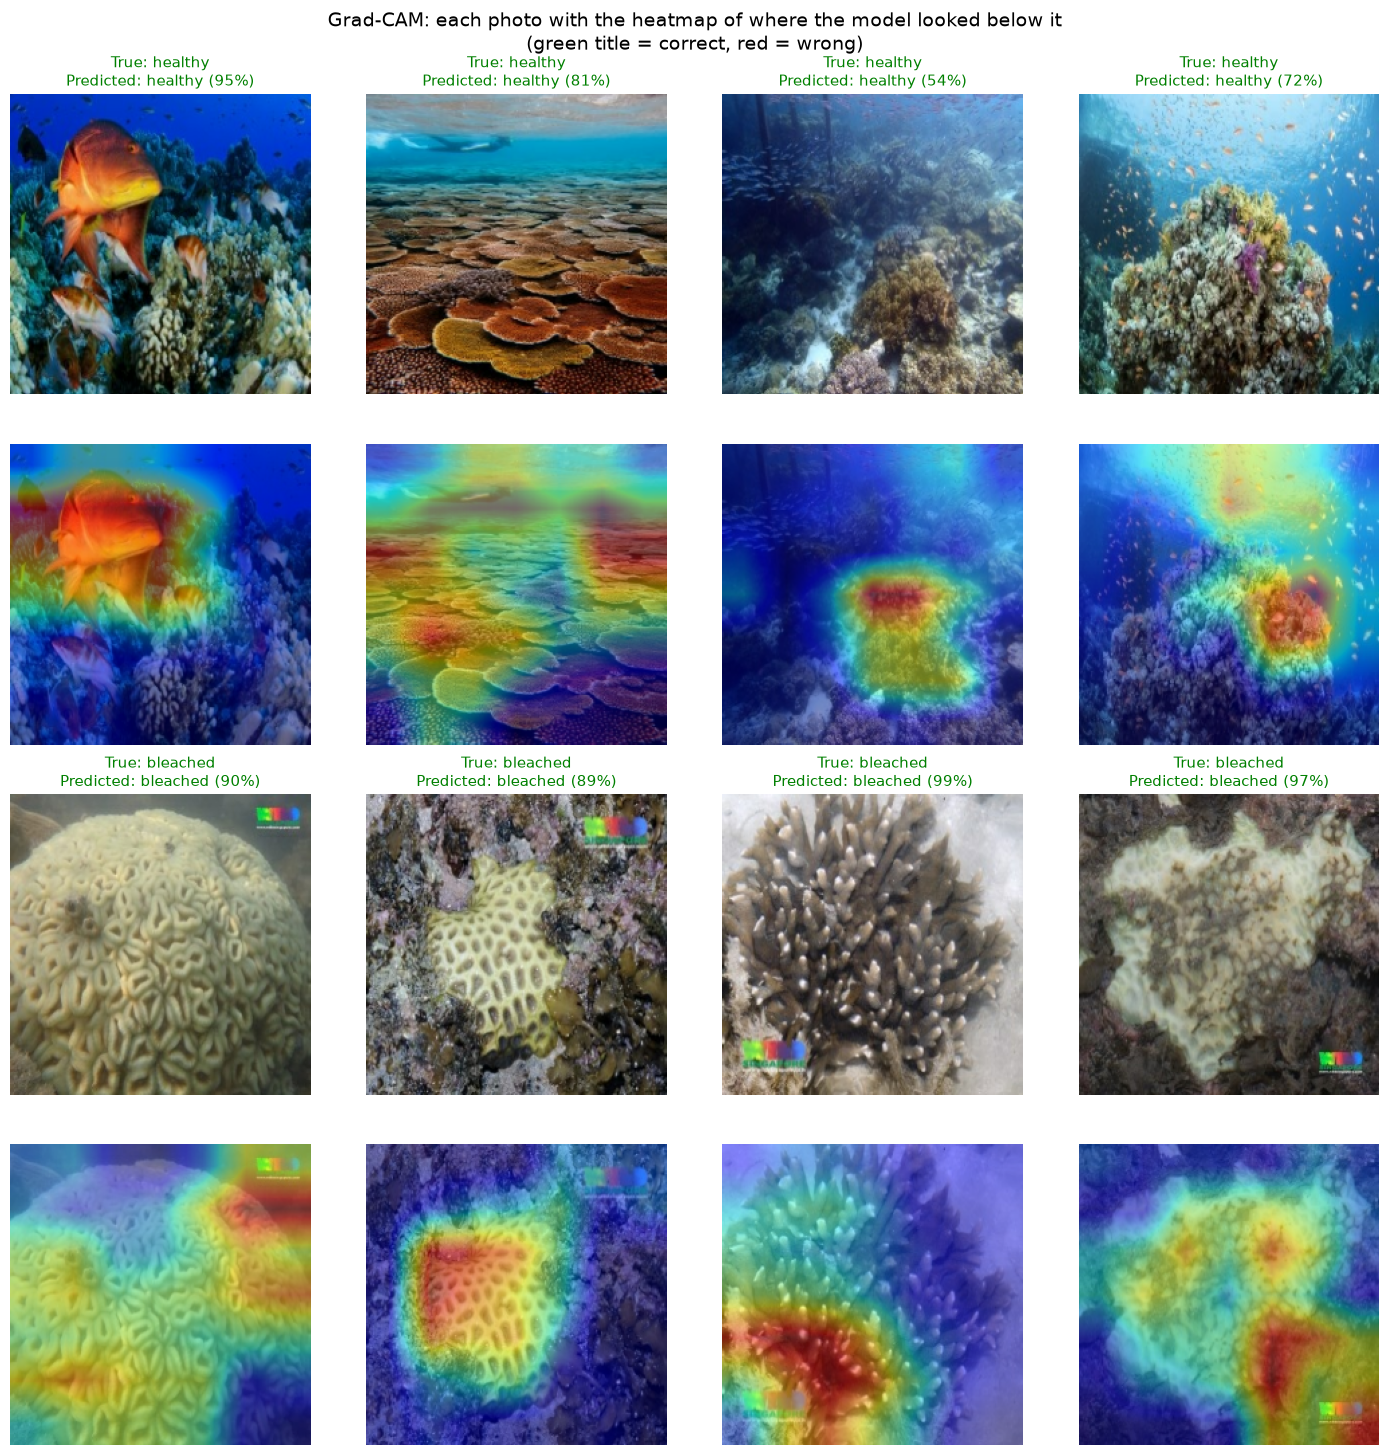

Misclassified test photos: 27 of 136
Saved figure: coral_outputs\figures\07_misclassified.jpg


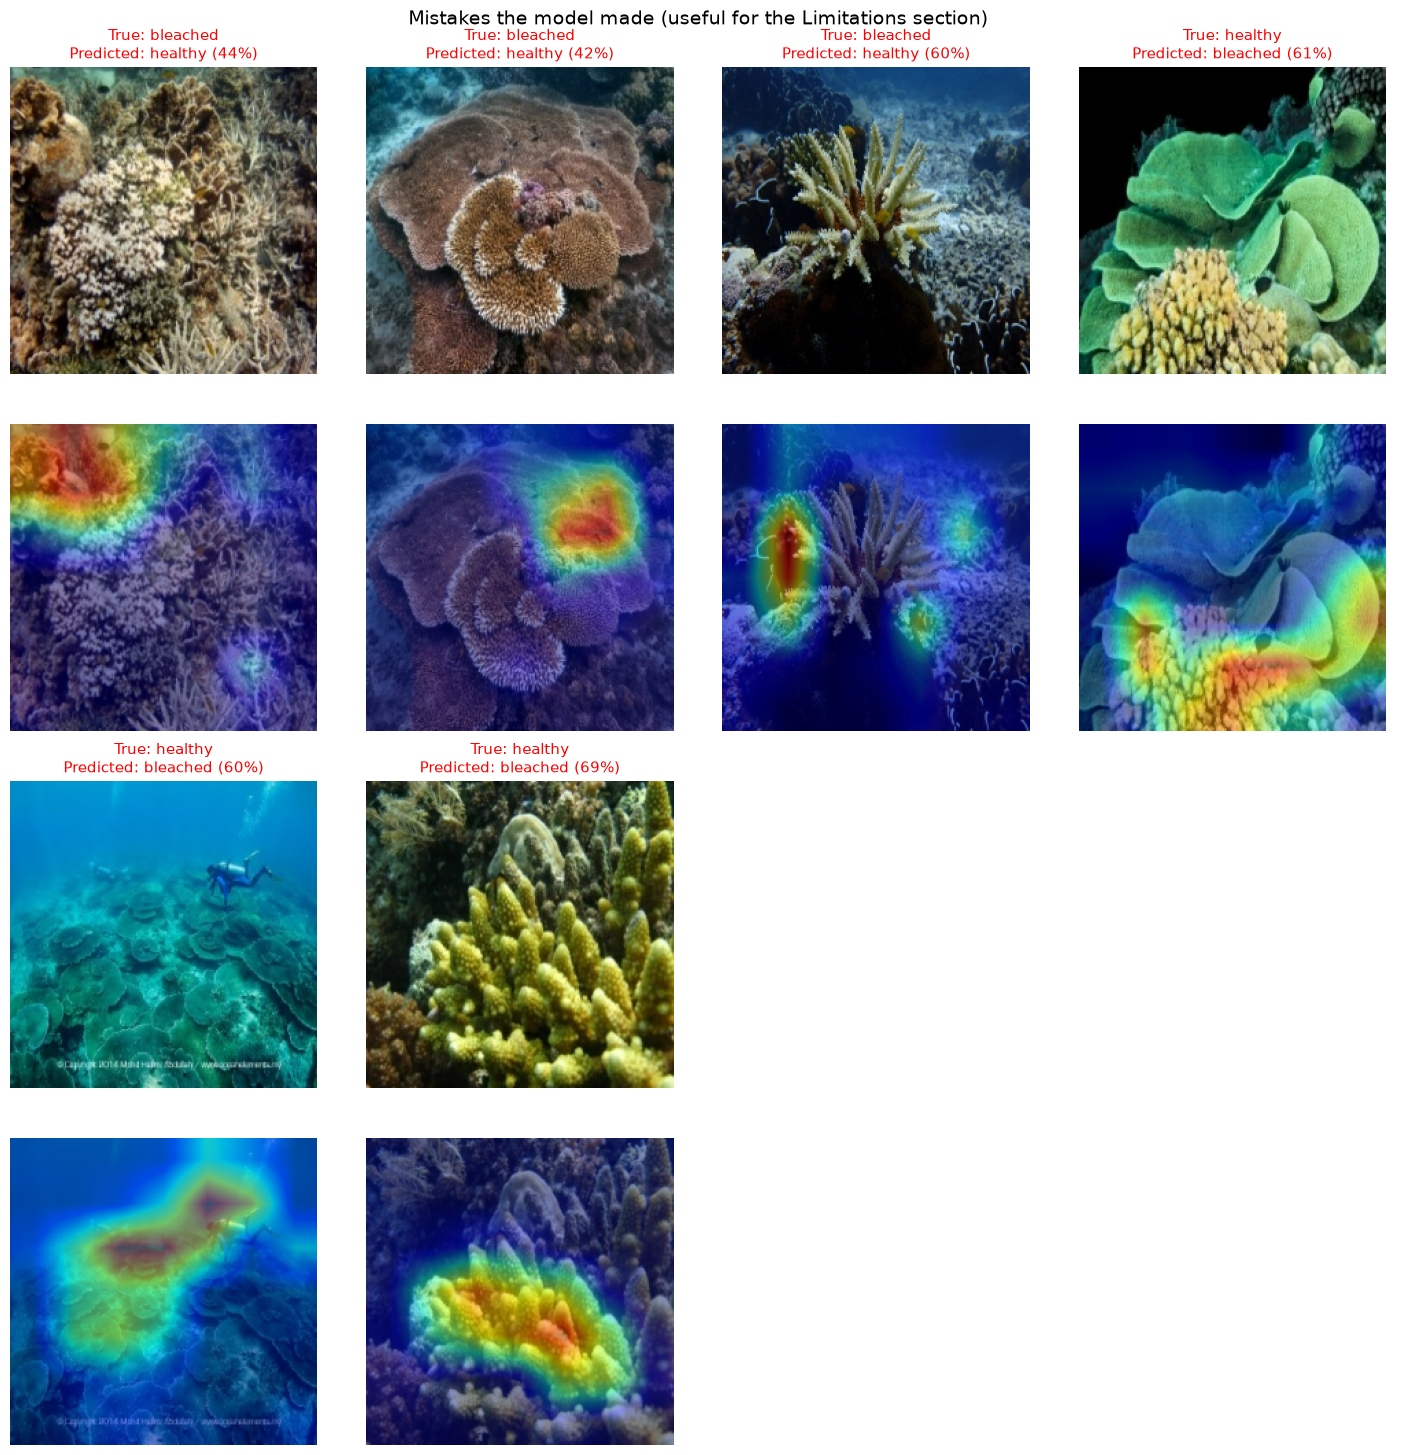

In [12]:
rescale_layer = model.get_layer("rescale")
gap_layer = model.get_layer("gap")
dense_layer = model.get_layer("prediction")

def grad_cam(img_array, explain_bleached=None):
    # img_array: (IMG_SIZE, IMG_SIZE, 3) float, pixels 0–255. Returns (P(bleached), heatmap 0–1).
    # explain_bleached: which class to explain; by default the class predicted at THRESHOLD.
    x = rescale_layer(tf.convert_to_tensor(img_array[None, ...], dtype=tf.float32))
    with tf.GradientTape() as tape:
        feature_maps = base_model(x, training=False)    # last conv layer output (7 x 7 x 1280)
        tape.watch(feature_maps)
        prob = dense_layer(gap_layer(feature_maps))[:, 0]
        if explain_bleached is None:
            explain_bleached = bool(prob[0] >= THRESHOLD)
        score = prob if explain_bleached else 1 - prob   # explain the predicted class
    grads = tape.gradient(score, feature_maps)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(feature_maps[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return float(prob[0]), cam.numpy()

def overlay_heatmap(img_uint8, cam, alpha=0.45):
    heat = Image.fromarray(np.uint8(cam * 255)).resize(img_uint8.shape[1::-1], Image.BILINEAR)
    heat = plt.cm.jet(np.asarray(heat) / 255.0)[..., :3]
    return np.uint8((1 - alpha) * img_uint8 + alpha * heat * 255)

def show_examples(idx_list, title, filename, per_row=4):
    # Each example: photo on top (with true and predicted label), Grad-CAM heatmap underneath.
    n = len(idx_list)
    cols = min(per_row, n)
    groups = int(np.ceil(n / cols))
    fig, axes = plt.subplots(2 * groups, cols, figsize=(3.6 * cols, 7.4 * groups), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for k, i in enumerate(idx_list):
        r, c = 2 * (k // cols), k % cols
        img, _ = load_image(test_p[i], test_y[i])
        img = img.numpy()
        prob = test_probs[i]                  # same prediction as in the evaluation above
        pred_idx = int(prob >= THRESHOLD)
        _, cam = grad_cam(img, explain_bleached=bool(pred_idx))
        pred = CLASS_NAMES[pred_idx]
        conf = prob if pred_idx else 1 - prob
        colour = "green" if pred_idx == test_y[i] else "red"
        axes[r, c].imshow(img.astype(np.uint8))
        axes[r, c].set_title(f"True: {CLASS_NAMES[test_y[i]]}\nPredicted: {pred} ({conf:.0%})", fontsize=11, color=colour)
        axes[r + 1, c].imshow(overlay_heatmap(img.astype(np.uint8), cam))
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    save_fig(filename)
    plt.show()

rng = np.random.default_rng(SEED)
picks = [int(i) for c in (0, 1) for i in rng.choice(np.where(test_y == c)[0], size=min(4, int((test_y == c).sum())), replace=False)]
show_examples(picks, "Grad-CAM: each photo with the heatmap of where the model looked below it\n(green title = correct, red = wrong)", "06_gradcam_examples.jpg")

wrong = np.where(test_pred != test_y)[0]
print(f"Misclassified test photos: {len(wrong)} of {len(test_y)}")
if len(wrong):
    show_examples([int(i) for i in wrong[:6]], "Mistakes the model made (useful for the Limitations section)", "07_misclassified.jpg")

## 10. Save the model and all outputs
This saves the trained model, a `model_info.json` file with every number for your report, and a few test photos for the demo app, then downloads everything as `coral_outputs.zip`.

In [13]:
model.save(os.path.join(OUTPUT_DIR, "coral_model.keras"))

sample_dir = os.path.join(OUTPUT_DIR, "samples")
os.makedirs(sample_dir, exist_ok=True)
for c, cls in enumerate(CLASS_NAMES):
    for k, i in enumerate(np.where(test_y == c)[0][:3]):
        shutil.copy(test_p[i], os.path.join(sample_dir, f"{cls}_example_{k + 1}.jpg"))

info = {
    "class_names": CLASS_NAMES,
    "threshold": round(THRESHOLD, 2),
    "tta": bool(USE_TTA),
    "img_size": IMG_SIZE,
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__,
    "dataset": f"kaggle.com/datasets/{KAGGLE_DATASET}",
    "images_used": {"total": int(len(paths)), **counts},
    "images_skipped": skipped,
    "split": {"train": int(len(train_y)), "validation": int(len(val_y)), "test": int(len(test_y))},
    "epochs_trained": {"stage1_head": stage1_epochs, "stage2_finetune": stage2_epochs},
    "training_settings": {"finetune_layers": FINETUNE_LAYERS, "label_smoothing": LABEL_SMOOTHING,
                          "augmentation": "flip, rotate 15%, zoom 15%, shift 10%"},
    "training_minutes": round(train_minutes, 1),
    "test_metrics": {
        "accuracy": round(test_acc, 4),
        "accuracy_at_0.5_threshold": round(test_acc_at_05, 4),
        "roc_auc": round(test_auc, 4),
        "bleached_precision": round(report["bleached"]["precision"], 4),
        "bleached_recall": round(report["bleached"]["recall"], 4),
        "healthy_precision": round(report["healthy"]["precision"], 4),
        "healthy_recall": round(report["healthy"]["recall"], 4),
        "macro_f1": round(report["macro avg"]["f1-score"], 4),
        "misclassified": int(len(wrong)),
    },
    "baseline_colour_only": {"accuracy": round(baseline_acc, 4), "roc_auc": round(baseline_auc, 4)},
}
with open(os.path.join(OUTPUT_DIR, "model_info.json"), "w") as f:
    json.dump(info, f, indent=2)
print(json.dumps(info, indent=2))

shutil.make_archive("coral_outputs", "zip", OUTPUT_DIR)
try:
    from google.colab import files
    files.download("coral_outputs.zip")
except ImportError:
    print("Saved coral_outputs.zip in", os.getcwd())

{
  "class_names": [
    "healthy",
    "bleached"
  ],
  "threshold": 0.59,
  "tta": true,
  "img_size": 224,
  "tensorflow_version": "2.21.0",
  "keras_version": "3.15.1",
  "dataset": "kaggle.com/datasets/vencerlanz09/healthy-and-bleached-corals-image-classification",
  "images_used": {
    "total": 905,
    "healthy": 423,
    "bleached": 482
  },
  "images_skipped": {
    "no class folder": 0,
    "duplicate": 18,
    "unreadable": 0
  },
  "split": {
    "train": 633,
    "validation": 136,
    "test": 136
  },
  "epochs_trained": {
    "stage1_head": 20,
    "stage2_finetune": 15
  },
  "training_settings": {
    "finetune_layers": 30,
    "label_smoothing": 0.05,
    "augmentation": "flip, rotate 15%, zoom 15%, shift 10%"
  },
  "training_minutes": 14.9,
  "test_metrics": {
    "accuracy": 0.8015,
    "accuracy_at_0.5_threshold": 0.7868,
    "roc_auc": 0.8804,
    "bleached_precision": 0.8571,
    "bleached_recall": 0.75,
    "healthy_precision": 0.7534,
    "healthy_recall": 0

## 11. (Optional) Live demo inside Colab
This is a backup if you can't run the Streamlit app on your laptop. Set `RUN_GRADIO_DEMO = True` in the settings cell and run this cell. It prints a public link that works on any phone or laptop for 72 hours.

In [14]:
if RUN_GRADIO_DEMO:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

    def predict(image):
        if image is None:
            return None, None
        img = Image.fromarray(image).convert("RGB")
        img.thumbnail((512, 512))
        arr = tf.image.resize(np.asarray(img, dtype=np.float32), (IMG_SIZE, IMG_SIZE)).numpy()
        batch = np.stack([arr, arr[:, ::-1]]) if USE_TTA else arr[None]
        prob = float(np.mean(model(batch, training=False)))
        _, cam = grad_cam(arr, explain_bleached=prob >= THRESHOLD)
        return {"Bleached": prob, "Healthy": 1 - prob}, overlay_heatmap(arr.astype(np.uint8), cam)

    gr.Interface(
        fn=predict,
        inputs=gr.Image(label="Coral photo"),
        outputs=[gr.Label(label="Prediction"), gr.Image(label="Where the model looked (Grad-CAM)")],
        title="Coral Bleaching Detector",
        description=f"Upload a coral photo to check whether it looks healthy or bleached "
                    f"(the model says 'bleached' above {THRESHOLD:.0%}).",
    ).launch(share=True)
else:
    print("Gradio demo skipped (set RUN_GRADIO_DEMO = True in the settings cell to launch it).")

Gradio demo skipped (set RUN_GRADIO_DEMO = True in the settings cell to launch it).
